# MuSiC: Python tutorial

Reference construction and default weighted-NNLS music_prop path. No ct.cov=TRUE, centered/normalized variants, recursive tree decomposition or MuSiC2.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
from pymusic_deconv import *


## Run the public functions
The example uses checked-in fixtures. Labels and matrix orientations are explicit. See function docstrings before substituting your own data.

(100, 3)
    converged  iterations
b1       True           1
b2       True           1
b3       True           1


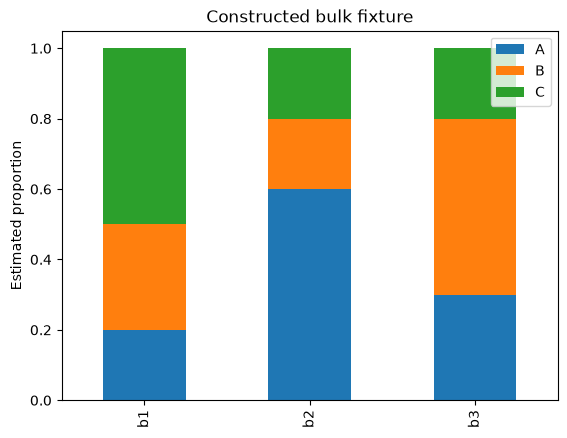

In [2]:
counts=pd.read_csv(ROOT/'data/reference.csv',index_col=0)
bulk=pd.read_csv(ROOT/'data/bulk.csv',index_col=0)
meta=pd.read_csv(ROOT/'data/metadata.csv',index_col=0)
basis=music_basis(counts,meta.ct,meta.donor)
result=music_prop(bulk,counts,meta.ct,meta.donor)
print(basis['design'].shape);print(result['diagnostics'])
result['proportions'].plot.bar(stacked=True);plt.ylabel('Estimated proportion');plt.title('Constructed bulk fixture');plt.show()


## Parameters and pitfalls
R uses one-based indices; Python integer indices are zero-based. Preserve biological-sample identities. Do not interpret descriptive factors or deconvolution fractions as differential-test p-values.

In [3]:
import inspect
import importlib
api=importlib.import_module('pymusic_deconv')
rows=[]
for name in api.__all__:
    function=getattr(api,name)
    if not inspect.isfunction(function): continue
    for parameter in inspect.signature(function).parameters.values():
        rows.append({'Python function':name,'parameter':parameter.name,'default':str(parameter.default),
                     'contract':inspect.getdoc(function)})
display(pd.DataFrame(rows))


,Python function,parameter,default,contract
0,music_basis,counts,<class 'inspect._empty'>,Build a genes-by-cell-types reference from gen...
1,music_basis,clusters,<class 'inspect._empty'>,Build a genes-by-cell-types reference from gen...
2,music_basis,samples,<class 'inspect._empty'>,Build a genes-by-cell-types reference from gen...
3,music_basis,nonzero,True,Build a genes-by-cell-types reference from gen...
4,music_basis,markers,None,Build a genes-by-cell-types reference from gen...
5,music_basis,select_ct,None,Build a genes-by-cell-types reference from gen...
6,music_basis,cell_size,None,Build a genes-by-cell-types reference from gen...
7,music_prop,bulk,<class 'inspect._empty'>,MuSiC proportions using multiple reference don...
8,music_prop,reference,<class 'inspect._empty'>,MuSiC proportions using multiple reference don...
9,music_prop,clusters,<class 'inspect._empty'>,MuSiC proportions using multiple reference don...
